# 모의시험 01 · 문의 이관 분류

독창적 가상 데이터와 자체 연습 문항입니다. 제공 샘플의 흐름을 참고했으며 원문 복제가 아닙니다.

14문항 · 90분 · 힌트 없이 진행

CSV 두 개와 노트북을 같은 폴더에 두세요. 커널 재시작 → 전체 실행 → 저장한 뒤 사이트에 제출하세요. 각 답안 다음 검증 셀은 실행 결과를 검사합니다. 검증 셀을 바꾸면 점수 신뢰도가 사라집니다. 공식 점수 예측이 아닌 자체 연습 점수입니다.

데이터: ticket_id 식별번호, created_at 접수일시, issue_type 문의유형, contact_channel 채널, membership_tier 등급, tenure_months 가입개월, monthly_spend 월금액(원), previous_tickets 과거 문의 수, wait_minutes 대기분, past_satisfaction_score 과거만족도(1~5), escalated 이관여부(0/1), resolution_hours 해결시간(시간). resolution_hours는 분류 입력에서 제외합니다.

In [210]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, confusion_matrix, mean_absolute_error
SET_ID='mock-01'
DATA_FILE="practice.csv"
MEMBERS_FILE="members.csv"
MODEL_FILE="best_mock-01.keras"

from pathlib import Path
import json as _json
from IPython.display import display as _display
_raw = pd.read_csv(DATA_FILE)
_grade_results = []
def _filled(d):
    x=d.copy()
    cols=['wait_minutes','past_satisfaction_score','monthly_spend']
    x[cols]=x[cols].fillna(x[cols].median())
    x['contact_channel']=x.contact_channel.fillna(x.contact_channel.mode().iloc[0])
    return x
def _plot_ok(fig,h,k1,k2,title,ylabel,labels=None):
    a=fig.axes[0]
    ls=a.get_lines()
    labels=labels or [k1,k2]
    return (len(ls)==2 and a.get_title()==title and a.get_xlabel()=='Epoch' and a.get_ylabel()==ylabel
      and np.allclose(ls[0].get_ydata(),h.history[k1]) and np.allclose(ls[1].get_ydata(),h.history[k2])
      and a.get_legend() is not None and [t.get_text() for t in a.get_legend().get_texts()]==labels)
def _grade_q(number,checks):
    items=[]
    for label,expr in checks:
        try:
            ok=bool(eval(expr,globals()))
            items.append({'label':label,'passed':ok,'detail':'검사 통과' if ok else '실행 결과가 지시와 다릅니다. 변수명·조건·파라미터를 확인하세요.'})
        except Exception as e:
            items.append({'label':label,'passed':False,'detail':type(e).__name__+': '+str(e)[:180]})
    report={'schema':'aice-lab-v1','setId':SET_ID,'question':number,'checks':items}
    _grade_results.append(report)
    _display({'application/json':report},raw=True)


## 1. 라이브러리 호출 (3점)

pandas를 pd, numpy를 np, seaborn을 sns, matplotlib.pyplot을 plt 별칭으로 불러오세요.

In [211]:
# 여기에 답안코드를 작성하고 실행하세요.
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [212]:
_grade_q(1, [['라이브러리 별칭', 'pd.__name__=="pandas" and np.__name__=="numpy" and sns.__name__=="seaborn" and plt.__name__=="matplotlib.pyplot"']])

## 2. 데이터 읽기 (5점)

DATA_FILE을 data에 읽고 처음 4행을 출력하세요.

In [213]:
# 여기에 답안코드를 작성하고 실행하세요.
data = pd.read_csv(DATA_FILE)
data.head(4)

,ticket_id,created_at,issue_type,contact_channel,membership_tier,tenure_months,monthly_spend,previous_tickets,wait_minutes,past_satisfaction_score,escalated,resolution_hours
0,T1901-0,2026-07-15 13:00:00,Delivery,Email,Gold,17,52400.0,1,47.4,4.3,0,11.65
1,T1901-1,2026-05-04 02:00:00,Account,Chat,Silver,3,30000.0,2,NaN,2.6,0,4.73
2,T1901-2,2026-05-19 21:00:00,Technical,Chat,Basic,33,25300.0,4,19.1,NaN,0,15.92
3,T1901-3,2026-08-15 01:00:00,Account,Email,Silver,42,81900.0,4,42.2,1.9,1,14.27


In [214]:
_grade_q(2, [['데이터 로드', 'data.equals(_raw)']])

## 3. 나란히 시각화 (6점)

fig_eda에 1행2열 그래프를 만드세요. 왼쪽 issue_type countplot, 오른쪽 wait_minutes histplot(bins=20). 제목은 Issue Count, Wait Distribution.

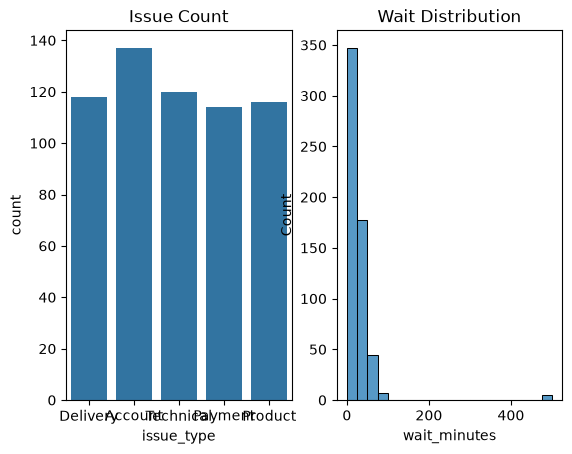

In [215]:
# 여기에 답안코드를 작성하고 실행하세요.
fig_eda, axes = plt.subplots(1,2)

sns.countplot(data=data, x="issue_type", ax=axes[0])
sns.histplot(data=data, x="wait_minutes", bins=20)

axes[0].set_title("Issue Count")
axes[1].set_title("Wait Distribution")
plt.show()


In [216]:
_grade_q(3, [['두 축과 제목', 'len(fig_eda.axes)==2 and [a.get_title() for a in fig_eda.axes]==["Issue Count","Wait Distribution"]'], ['지정한 그래프 데이터', 'len(fig_eda.axes[0].patches)==5 and len(fig_eda.axes[1].patches)==20 and fig_eda.axes[1].get_xlabel()=="wait_minutes"']])

## 4. 분포 시각화 (6점)

fig_box에 x=escalated, y=past_satisfaction_score인 boxplot을 그리세요.

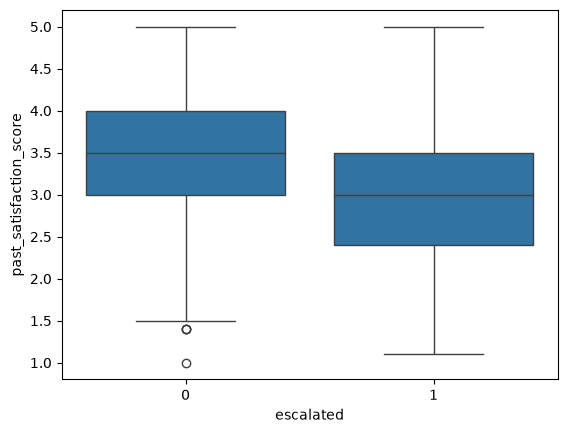

In [217]:
# 여기에 답안코드를 작성하고 실행하세요.
fig_box = plt.figure()

sns.boxplot(data=data, x="escalated", y="past_satisfaction_score")

plt.show()

In [218]:
_grade_q(4, [['박스플롯 축', 'fig_box.axes[0].get_xlabel()=="escalated" and fig_box.axes[0].get_ylabel()=="past_satisfaction_score"'], ['박스 생성', 'len(fig_box.axes[0].patches)>=2']])

## 5. 이상치와 불필요 컬럼 (6점)

완전 중복 행을 제거하고 wait_minutes가 300 이상인 행을 제거하세요. wait_minutes 결측 행은 유지합니다. ticket_id,created_at을 삭제해 data_temp에 저장하고 인덱스를 초기화하세요.

In [219]:
# 여기에 답안코드를 작성하고 실행하세요.
data = data.drop_duplicates()
data = data[(data["wait_minutes"]<300)|(data["wait_minutes"].isna())]

data_temp = data.drop(columns=["ticket_id", "created_at"]).reset_index(drop=True)

data.isna().sum()

ticket_id                   0
created_at                  0
issue_type                  0
contact_channel            10
membership_tier             0
tenure_months               0
monthly_spend              12
previous_tickets            0
wait_minutes               24
past_satisfaction_score    18
escalated                   0
resolution_hours            0
dtype: int64

In [220]:
_grade_q(5, [['정확한 전처리 결과', 'data_temp.equals(_raw.drop_duplicates().loc[lambda d:d.wait_minutes.isna() | (d.wait_minutes<300)].drop(columns=["ticket_id","created_at"]).reset_index(drop=True))']])

## 6. 결측치 대체 (6점)

data_temp의 전체 결측 수를 answer6에 저장하세요. 복사본 data_na의 wait_minutes,past_satisfaction_score,monthly_spend는 각 중앙값, contact_channel은 최빈값으로 채우세요.

In [221]:
# 여기에 답안코드를 작성하고 실행하세요.
answer6 = data_temp.isna().sum().sum()

data_na = data_temp.copy()

median_cols = ["wait_minutes", "past_satisfaction_score", "monthly_spend"]

data_na[median_cols] = data_na[median_cols].fillna(data_na[median_cols].median())

data_na["contact_channel"] = data_na["contact_channel"].fillna(data_na["contact_channel"].mode().iloc[0])



In [222]:
_grade_q(6, [['원래 결측 수', 'answer6==data_temp.isna().sum().sum()'], ['대체 결과', 'data_na.equals(_filled(data_temp))']])

## 7. 범주 통합과 원핫 (6점)

data_na의 Payment,Account를 Account/Billing으로 통합하세요. resolution_hours을 제외하고 issue_type,contact_channel,membership_tier를 원핫 인코딩해 preset에 저장하세요. drop_first=False,dtype=int.

In [223]:
# 여기에 답안코드를 작성하고 실행하세요.
data_na.loc[
    data_na["issue_type"].isin(["Payment","Account"]),
    "issue_type"
] = "Account/Billing"

In [224]:
preset = data_na.drop(columns=["resolution_hours"])
preset = pd.get_dummies(
    preset,
    ["issue_type", "contact_channel", "membership_tier"],
    drop_first=False,
    dtype=int
)

In [225]:
_grade_q(7, [['통합', 'not data_na.issue_type.isin(["Payment","Account"]).any() and "Account/Billing" in data_na.issue_type.values'], ['원핫 결과', 'preset.equals(pd.get_dummies(data_na.drop(columns="resolution_hours"),columns=["issue_type","contact_channel","membership_tier"],dtype=int))']])

## 8. 훈련·검증 분리 (6점)

preset의 escalated을 y, 나머지를 X에 저장하세요. 70:30,random_state=7,stratify=y로 X_train,X_valid,y_train,y_valid에 분리하세요.

In [226]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import train_test_split

X = preset.drop(columns=["escalated"])
y = preset["escalated"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=7,
    stratify=y
)

In [227]:
_grade_q(8, [['타깃 분리', 'y.equals(preset["escalated"]) and X.equals(preset.drop(columns="escalated"))'], ['지정한 분할', 'np.array_equal(X_train.index,train_test_split(X,y,test_size=.3,random_state=7,stratify=y)[0].index) and np.array_equal(y_valid,train_test_split(X,y,test_size=.3,random_state=7,stratify=y)[3])']])

## 9. 스케일러 오류 수정 (6점)

ss에 StandardScaler를 생성하세요. 훈련을 fit_transform해 X_train_scaled, 검증을 transform해 X_valid_scaled에 저장하세요. 검증 최댓값의 반올림을 answer9에 저장하세요.

In [228]:
# 아래 코드의 오류를 정정하고 실행하세요.
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
X_train_scaled=ss.fit_transform(X_train)
X_valid_scaled=ss.transform(X_valid)  # 검증 기준을 수정하세요.
answer9=round(np.max(X_valid_scaled))


In [229]:
_grade_q(9, [['훈련 변환', 'np.allclose(X_train_scaled,StandardScaler().fit_transform(X_train))'], ['검증 같은 기준', 'np.allclose(X_valid_scaled,StandardScaler().fit(X_train).transform(X_valid))'], ['최댓값 반올림', 'answer9==round(np.max(X_valid_scaled))']])

## 10. GridSearch 모델링 (12점)

gs_dt,gs_rf에 결정트리·랜덤포레스트 분류기를 GridSearchCV로 학습하세요. 공통: random_state7, 깊이[3,5], 최소분할[2,5],cv3,scoring accuracy,n_jobs -1. RF 트리30개. 스케일된 훈련 사용.

In [230]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

params = {
    "max_depth":[3,5],
    "min_samples_split":[2,5]
}

gs_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=7),
    params,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

gs_rf = GridSearchCV(
    RandomForestClassifier(random_state=7, n_estimators=30),
    params,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

gs_dt.fit(X_train_scaled, y_train);
gs_rf.fit(X_train_scaled, y_train);


In [231]:
_grade_q(10, [['두 탐색 설정', 'all(g.cv==3 and g.scoring=="accuracy" and g.n_jobs==-1 and g.param_grid=={"max_depth":[3,5],"min_samples_split":[2,5]} and g.estimator.random_state==7 for g in [gs_dt,gs_rf])'], ['최적 모델 학습', 'hasattr(gs_dt,"best_estimator_") and hasattr(gs_rf,"best_estimator_") and gs_rf.estimator.n_estimators==30']])

## 11. 변수 중요도 (8점)

gs_rf.best_estimator_의 변수 중요도를 fi에 feature,importance 컬럼으로 만들고 내림차순 상위10개를 남기세요. fig_importance에 가로 barplot. 최상위 이름을 answer11에 저장하세요.

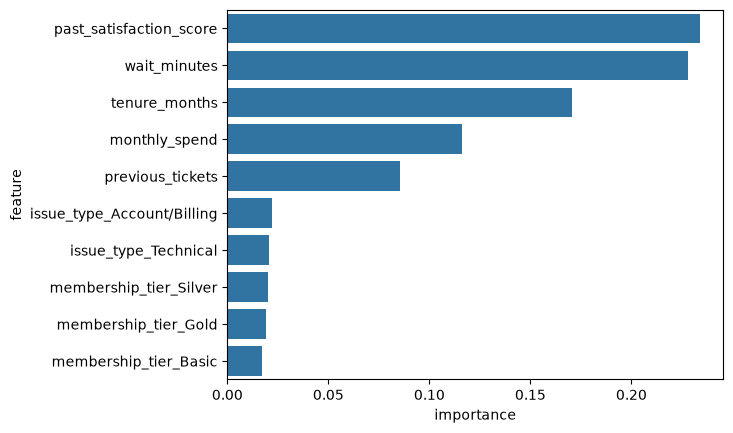

In [232]:
# 여기에 답안코드를 작성하고 실행하세요.
fi = pd.DataFrame({
    "feature":X_train.columns,
    "importance":gs_rf.best_estimator_.feature_importances_
}).sort_values("importance", ascending=False).head(10).reset_index(drop=True)

fig_importance = plt.figure()

sns.barplot(data=fi, x="importance", y="feature")
plt.show()

answer11 = "past_satisfaction_score"

In [233]:
_grade_q(11, [['변수 이름과 점수', 'fi.reset_index(drop=True).equals(pd.DataFrame({"feature":X.columns,"importance":gs_rf.best_estimator_.feature_importances_}).sort_values("importance",ascending=False).head(10).reset_index(drop=True))'], ['최상위와 그래프', 'answer11==fi.iloc[0]["feature"] and fig_importance.axes[0].get_xlabel()=="importance" and len(fig_importance.axes[0].patches)==len(fi)']])

## 12. 모델 평가 (8점)

두 모델로 검증 예측을 y_pred_dt,y_pred_rf에 저장하세요. Accuracy를 dt_score,rf_score에 계산하고 더 좋은 모델을 answer12에 "dt" 또는 "rf"로 저장하세요. 동점은 "dt".

In [234]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.metrics import accuracy_score

y_pred_dt = gs_dt.predict(X_valid_scaled)
y_pred_rf = gs_rf.predict(X_valid_scaled)

dt_score = accuracy_score(y_valid, y_pred_dt)
rf_score = accuracy_score(y_valid, y_pred_rf)

print(f"{dt_score} | {rf_score}")
answer12 = "rf"

0.8156424581005587 | 0.8212290502793296


In [235]:
_grade_q(12, [['두 모델 예측', 'np.array_equal(y_pred_dt,gs_dt.best_estimator_.predict(X_valid_scaled)) and np.array_equal(y_pred_rf,gs_rf.best_estimator_.predict(X_valid_scaled))'], ['평가지표', 'np.isclose(dt_score,accuracy_score(y_valid,y_pred_dt)) and np.isclose(rf_score,accuracy_score(y_valid,y_pred_rf))'], ['더 좋은 모델', 'answer12==("rf" if rf_score > dt_score else "dt")']])

## 13. 딥러닝 구성과 학습 (16점)

Input → Dense32 relu → Dropout0.2 → Dense16 relu → Dense2 sigmoid를 model로 만드세요. adam,loss=binary_crossentropy,metrics=[accuracy]. estop: val_loss,patience5,restore_best_weights=True. checkpoint: MODEL_FILE,val_loss,save_best_only=True. y_train_dl,y_valid_dl은 to_categorical(...,num_classes=2)로 변환하세요. (제공 분류 샘플의 2출력 sigmoid 지시 변형입니다.) history에 epochs30,batch_size32,validation_data와 두 콜백으로 학습하세요.

In [236]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(2, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

estop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    filepath=MODEL_FILE,
    monitor="val_loss",
    save_best_only=True
)

y_train_dl = to_categorical(y_train, num_classes=2)
y_valid_dl = to_categorical(y_valid, num_classes=2)

history = model.fit(
    X_train_scaled,
    y_train_dl,
    epochs=30,
    batch_size=32,
    validation_data=(X_valid_scaled, y_valid_dl),
    callbacks=[estop, checkpoint]
)

Epoch 1/30


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.5649 - loss: 0.7317 - val_accuracy: 0.6480 - val_loss: 0.6805
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6755 - loss: 0.6471 - val_accuracy: 0.7095 - val_loss: 0.6130
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7380 - loss: 0.5893 - val_accuracy: 0.7709 - val_loss: 0.5635
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7788 - loss: 0.5536 - val_accuracy: 0.8101 - val_loss: 0.5290
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8149 - loss: 0.5128 - val_accuracy: 0.8156 - val_loss: 0.5064
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8149 - loss: 0.5014 - val_accuracy: 0.8156 - val_loss: 0.4907
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8125 - loss: 0.4836 - val_accuracy: 0.8156 - val_loss: 0.4789
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8101 - loss: 0.4694 - val_accuracy: 0.8156 - val_loss: 0.4711
Ep

In [237]:
_grade_q(13, [['층 구성', '[(l.units,l.activation.__name__) for l in model.layers if hasattr(l,"units")]==[(32,"relu"),(16,"relu"),(2,"sigmoid")] and any(type(l).__name__=="Dropout" and np.isclose(l.rate,.2) for l in model.layers)'], ['컴파일', 'model.loss=="binary_crossentropy" and type(model.optimizer).__name__=="Adam"'], ['정답 형태', 'np.asarray(y_train_dl).shape==(len(y_train),2) and np.asarray(y_valid_dl).shape==(len(y_valid),2)'], ['콜백', 'estop.monitor=="val_loss" and estop.patience==5 and estop.restore_best_weights and checkpoint.monitor=="val_loss" and checkpoint.save_best_only and str(checkpoint.filepath)==MODEL_FILE'], ['검증 학습과 저장', '"val_loss" in history.history and history.params["epochs"]==30 and 1<=len(history.epoch)<=30 and Path(MODEL_FILE).is_file()']])

## 14. 학습 그래프 (6점)

fig_history에 accuracy,val_accuracy 두 곡선을 그리세요. 범례는 acc,val_acc. 제목 Model Accuracy, X축 Epoch,Y축 Accuracy.

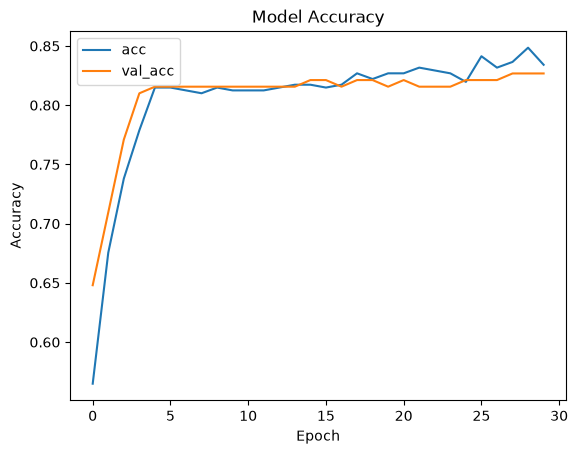

In [238]:
# 빈칸 문자열 __FILL__을 알맞게 바꾸고 그래프의 제목·축·범례를 완성하세요.
fig_history,ax=plt.subplots()
ax.plot(history.history['accuracy'],label='acc')
ax.plot(history.history['val_accuracy'],label='val_acc')

plt.legend()

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.show()

In [239]:
_grade_q(14, [['정확한 학습 그래프', '_plot_ok(fig_history,history,"accuracy","val_accuracy","Model Accuracy","Accuracy",[\'acc\', \'val_acc\'])']])

## 제출
검증 결과를 포함한 상태로 저장하세요. VS Code에서 실행이 중단되면 오류를 고친 뒤 다시 전체 실행하세요. 설치가 필요하면 사이트의 환경 설정 안내를 확인하세요.